# Learning fever from sparse labels, with rules about the course of the disease

**The problem.** A hospital ward. Each patient spends a few days in it, from admission (day 0) to discharge: we call these days the patient's **stay**. Every day we observe two things: one temperature reading, and whether the patient got a treatment that day. We want to know, for every day of every stay, whether the patient had **fever**.

Two things make it hard:
- **The readings are noisy:** around 38.1 °C on a day with fever and 36.9 °C on a day without, with a standard deviation of 1 °C. A threshold at 37.5 °C on a single reading is right only about 73% of the time.
- **Almost no labels:** the reading and the treatment are known for every day, but whether the patient had fever is known only for 2% of the days (never day 0), where a doctor wrote it down: these are the labels. With 200 training patients that is about 20 labelled days in total, so most patients have none.

What we do know is how the disease goes, written as three rules. The question is how much these rules can make up for the missing labels.

**How the disease goes** (the data is synthetic, generated this way):
- every patient is admitted with fever, which would last 1 to 6 days;
- about 55% of the patients get a treatment on day 0, 1 or 2, while the fever is on; the treatment ends the fever within two days;
- once the fever is gone it doesn't come back; the patient stays 1 to 4 more days and is discharged.

So a stay lasts 2 to 10 days.

**Why the disease is this simple.** The data is made so that the rules are exactly true. Then, when a rule is added or removed, any change in the results comes from that rule:
- the treatment always works in two days, so "no fever two days after a treatment" is a rule about specific, known days;
- there is no relapse, so "once the fever is gone it doesn't come back" is exactly true. Section 7 then adds relapses on purpose, to see what a rule that is partly wrong does;
- every patient is admitted with fever, so the rule "fever on day 0" is exactly true. It also means that every patient, even one without labels, has one day known to have fever.

A real ward is messier: the point here is to see each rule at work.

**The network.** `Fever` reads the whole stay of one patient, the reading and the treatment of every day, and returns one number in [0, 1] per day: the truth degree of "this patient had fever on this day". Inside, it is a small bidirectional GRU (a recurrent network that reads the days forwards and backwards), so its answer for one day can use the readings of the days around it (Section 2). It is scored on 2,000 new patients.

**The rules**, each about different days of a stay:

| rule | what it says | the days it speaks about |
|---|---|---|
| admitted with fever | every patient has fever on day 0 | day 0 |
| no relapse | once a day has no fever, no later day has fever | the days after the first recovery |
| treatment works | two days after a treatment, there is no fever | the day two days after a treatment |

Section 3 writes them as sLTN formulas.

**The comparison.** The same network is trained in six ways:
- **bce:** binary cross-entropy on the labelled days, without logic;
- **labels:** the labelled days only, written as logical statements ("patient 12 had fever on day 3"). This is sLTN without any knowledge;
- **rules:** the labelled days and the three rules;
- **− one rule:** the labelled days and two of the three rules, once for each rule left out (three models).

**What this example shows:**
- **Labels and rules in one objective.** The few labelled days are written as logical facts ("patient 12 had fever on day 3"), and the rules as statements about every day. sLTN trains the network to satisfy both, so the rules supervise the days nobody labelled.
- **Two structural dimensions.** Patients and days are both dimensions, so a label or a rule can speak about one day of one patient (Section 3).
- **A network that reads a whole sequence and answers for every step.** `Fever` consumes the `Day` dimension and produces it again: it takes a whole stay and returns one truth degree per day, and the rules then constrain its output day by day (Sections 2 and 3).
- **Guards that are conjunctions.** A guard such as "a treatment day, the day two days later, and that day is in the stay" is written as a conjunction of simple relations, and restricts a rule to the days it concerns. sLTN evaluates guards with the exact connectives, so a guard is exactly 0 where it is false (Section 3).
- **Sequences of different lengths.** Stays last from 2 to 10 days; Section 3 shows how to keep the missing days out of the network and out of the rules.
- **Measuring what each rule contributes.** Leaving out one rule at a time, and scoring the days each rule concerns, shows what each rule adds (Section 6).
- **Wrong knowledge.** A rule that is false for 30% of the patients: when it is harmless, and when it hurts (Section 7).

Everything runs on CPU, 10 seeds, in about 15 minutes.

In [1]:
import time

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

import sltn
from sltn import KB, Interpretation, Logic, Signature
from sltn.interpretation.operators.aggregator import AggregPMeanError

CONFIG = dict(
    n_train=200,       # training patients
    n_test=2000,       # test patients, new ones
    noise=1.0,         # standard deviation of a reading, in °C
    label_frac=0.02,   # labelled days (never day 0)
    epochs=300,        # full-batch Adam steps
    lr=1e-2,
    p_agg=4,           # pMeanError exponent for ∀ over patients and over days
    seeds=list(range(10)),
)

## 1. Data

- **Lengths.** A stay ends 1 to 4 days after the last fever day, so lengths vary from 2 to 10 days, and up to 14 with a relapse. Stays are padded to the longest one; `valid` marks the real days.
- **Treatment.** `treated_on[n, t]` is 1 on the day patient `n` is treated. It is observed: every model gets it as an input.
- **Relapse (`relapse`, 0 except in Section 7).** With this probability, a 1–2 day fever comes back 1–2 days after recovery. It never falls on the day the treatment rule speaks about, so it breaks only "no relapse".
- **Hidden:** the true fever, used to make the labels and to score the models.

In [2]:
def make_ward(n, label_frac, relapse, g, noise):
    # Stays padded to the longest one: a dict of [n, T] tensors.
    dur = torch.randint(1, 7, (n,), generator=g)                       # fever days 1..6, untreated
    treat_day = torch.randint(0, 3, (n,), generator=g)                 # day 0, 1 or 2
    treated = (torch.rand(n, generator=g) < 0.6) & (treat_day < dur)   # treated during the fever
    dur = torch.where(treated, torch.minimum(dur, treat_day + 2), dur) # no fever from treat_day + 2
    stay_after = torch.randint(1, 5, (n,), generator=g)                # days after recovery 1..4
    has_relapse = torch.rand(n, generator=g) < relapse
    rel_len = torch.randint(1, 3, (n,), generator=g)                   # a relapse lasts 1..2 days
    rel_gap = torch.randint(1, 3, (n,), generator=g)                   # after 1..2 days without fever
    rel_start = torch.where(treated, torch.maximum(dur + rel_gap, treat_day + 3), dur + rel_gap)
    length = torch.where(has_relapse, rel_start + rel_len, dur) + stay_after
    T = int(length.max())                                              # padding: every stay is padded to the longest one
    days = torch.arange(T)[None]
    valid = days < length[:, None]                                     # True on the real days of a stay, False on padding
    fever = days < dur[:, None]
    rs = rel_start[:, None]
    fever |= has_relapse[:, None] & (days >= rs) & (days < rs + rel_len[:, None])
    fever &= valid                                                     # padding: no fever on padded days
    temp = 36.9 + 1.2 * fever.float() + noise * torch.randn(n, T, generator=g)  # padding: padded days get a random reading too; ground() sets it to 0
    labelled = (torch.rand(n, T, generator=g) < label_frac) & valid    # padding: labels only on real days
    labelled[:, 0] = False
    treated_on = treated[:, None] & (days == treat_day[:, None]) & valid  # padding: treatments only on real days
    return dict(temp=temp, valid=valid, fever=fever, labelled=labelled, length=length,
                treated_on=treated_on, recovery=dur)


def wards(seed, noise=CONFIG["noise"], relapse=0.0):
    tr = make_ward(CONFIG["n_train"], CONFIG["label_frac"], relapse, torch.Generator().manual_seed(1000 + seed), noise)
    te = make_ward(CONFIG["n_test"], CONFIG["label_frac"], relapse, torch.Generator().manual_seed(5000 + seed), noise)
    return tr, te


tr, te = wards(0)
v = tr["valid"]                                                        # padding: the statistics below use real days only
print(f"training ward, seed 0: {CONFIG['n_train']} patients, {int(v.sum())} days, "
      f"{int(tr['labelled'].sum())} labelled; {int(tr['labelled'].any(1).sum())} patients have a labelled day")
print(f"stay length {tr['length'].min()}–{tr['length'].max()} days, fever on {tr['fever'][v].float().mean():.0%} of the days, "
      f"{tr['treated_on'].any(1).float().mean():.0%} of the patients treated")
print(f"threshold 37.5 °C on one reading: accuracy {((tr['temp'] > 37.5) == tr['fever'])[v].float().mean():.2f}")

training ward, seed 0: 200 patients, 1070 days, 16 labelled; 16 patients have a labelled day
stay length 2–9 days, fever on 55% of the days, 54% of the patients treated
threshold 37.5 °C on one reading: accuracy 0.73


One treated patient. The shaded days have fever (hidden from the models); the dashed line is the treatment, and "no fever from two days after it" is what the treatment rule says. Like most patients, this one has no labelled day: only the rules say anything about its days.

The readings are noisy. A circled reading is on the wrong side of 37.5 °C: here day 1 reads below 37 °C although the patient has fever. On the right, the readings of all training days: the two distributions overlap, which is why a threshold on one reading is right only about 73% of the time.

A single reading can mislead, but its neighbours help. Fever lasts several days, so a low reading between two high ones, like day 1 here, is more likely a noisy fever day than a day without fever. This is why `Fever` reads the whole stay (Section 2) instead of one reading at a time.

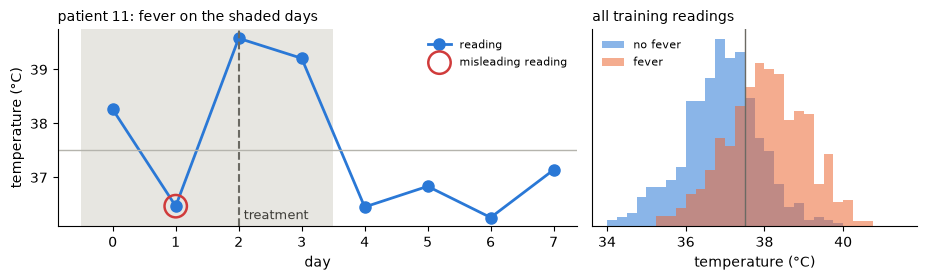

day      : [0, 1, 2, 3, 4, 5, 6, 7]
reading  : [38.3, 36.5, 39.6, 39.2, 36.5, 36.8, 36.3, 37.1]
fever    : [1, 1, 1, 1, 0, 0, 0, 0] (hidden)
labelled : [0, 0, 0, 0, 0, 0, 0, 0]


In [3]:
k = int(torch.nonzero(tr["treated_on"].any(1) & (tr["length"] >= 7)).flatten()[0])
L = int(tr["length"][k])
temp_k, fever_k = tr["temp"][k, :L], tr["fever"][k, :L]
misleading = (temp_k > 37.5) != fever_k                              # on the wrong side of 37.5 °C
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(9.5, 2.9), gridspec_kw=dict(width_ratios=[1.6, 1]))

for t in range(L):
    if fever_k[t]:
        ax.axvspan(t - 0.5, t + 0.5, color="#e7e6e1", lw=0)
ax.plot(range(L), temp_k, color="#2a78d6", lw=2, marker="o", ms=8, label="reading")
ax.scatter(torch.nonzero(misleading).flatten(), temp_k[misleading], s=260, facecolors="none",
           edgecolors="#d03b3b", lw=1.8, zorder=3, label="misleading reading")
t_treat = int(torch.nonzero(tr["treated_on"][k]).flatten()[0])
ax.axvline(t_treat, color="#6b6a63", ls="--", lw=1.5)
ax.text(t_treat + 0.08, ax.get_ylim()[0] + 0.08, "treatment", fontsize=9, color="#3d3c37", va="bottom")
ax.axhline(37.5, color="#b5b4ad", lw=1)
ax.set_xticks(range(L)); ax.set_xlabel("day"); ax.set_ylabel("temperature (°C)")
ax.set_title(f"patient {k}: fever on the shaded days", fontsize=10, loc="left")
ax.legend(fontsize=8, frameon=False, loc="upper right")

v = tr["valid"]
bins = torch.linspace(34, 41.5, 31)
for is_fever, label, color in ((False, "no fever", "#2a78d6"), (True, "fever", "#eb6834")):
    ax2.hist(tr["temp"][v & (tr["fever"] == is_fever)], bins=bins, density=True,
             color=color, alpha=0.55, label=label)
ax2.axvline(37.5, color="#6b6a63", lw=1)
ax2.set_xlabel("temperature (°C)"); ax2.set_yticks([])
ax2.set_title("all training readings", fontsize=10, loc="left")
ax2.legend(fontsize=8, frameon=False, loc="upper left")
for a in (ax, ax2):
    for s in ("top", "right"):
        a.spines[s].set_visible(False)
plt.tight_layout(); plt.show()
print("day      :", list(range(L)))
print("reading  :", [round(x, 1) for x in temp_k.tolist()])
print("fever    :", fever_k.int().tolist(), "(hidden)")
print("labelled :", tr["labelled"][k, :L].int().tolist())

## 2. The network

`Fever` reads a whole stay and returns one truth degree per day, so it can use the neighbouring days to decide an ambiguous reading. Its input on each day is `(temperature, treated, valid)`:
- **temperature and treated** are what it reads. It gets the treatment because of the treatment rule, which asks for "no fever" on one specific day: two days after a treatment. Without the treatment as input, the network can't tell which day that is. It sees only readings, and a noisy high reading on that day looks like a reading on a fever day. To lower its answer there, it has to lower it on every day that looks the same, fever days included: for those, the rule acts like a wrong "no fever" label. With the treatment as input, it can lower its answer two days after a treatment only. An earlier version without this input was indeed hurt by the treatment rule. In general, a rule can only be satisfied if the network can tell apart the cases the rule treats differently.
- **valid** marks the real days. The network packs each stay to its true length, so the padding never enters the GRU, and returns 0 on padded days. On real days it gives exactly the values it gives on the stay alone, without padding.

In [4]:
class FeverNet(nn.Module):
    # [B, Day, 3] -> [B, Day, 1], one truth degree per day.
    # B: patients; Day: days of the longest stay (padded); 3: (temperature, treated, valid)
    def __init__(self):
        super().__init__()
        self.gru = nn.GRU(2, 16, batch_first=True, bidirectional=True)
        self.out = nn.Linear(32, 1)

    def forward(self, v):
        x = torch.cat([v[..., :1] - 37.5, v[..., 1:2]], -1)          # temperature, treated
        valid = v[..., 2]                                            # padding: 1 on real days, 0 on padded days
        lengths = valid.sum(1).long().clamp(min=1).cpu()             # padding: the true length of each stay
        h, _ = self.gru(pack_padded_sequence(x, lengths, batch_first=True, enforce_sorted=False))  # padding: the GRU reads each stay only up to its true length
        h, _ = pad_packed_sequence(h, batch_first=True, total_length=v.shape[1])  # padding: back to [B, Day, 32], zeros on padded days
        return torch.sigmoid(self.out(h)) * valid.unsqueeze(-1)      # padding: truth degree 0 on padded days

## 3. sLTN: the rules, for stays of different lengths

**Signature:**
- **`Patient` and `Day` are both dimensions**, and the observations are a constant `obs` over `[Patient, Day]`: for each patient and day, the reading, the treatment and `valid` (the 3 values `Fever` receives, below). A label is about one day of one patient, so the labels are relations over `(patient, day)`, and a structural relation can only range over dimensions: so the patients are a dimension too.
- **`Fever`** consumes and produces `Day`: it receives a whole stay `[B, Day, 3]` and returns `[B, Day, 1]`. `p` isn't consumed, so the patients form the batch `B`; `Day` is the number of days of the longest stay, and the 3 values of a day are the temperature, the treatment (1 on the day of the treatment) and `valid` (1 on real days).
- `Fever(obs[p, d])[d]` is the network's output on the whole stay of patient `p`, with its day axis named `d`; `[d=0]` then keeps day 0 only.

**Relations.** All are 0/1 masks computed from what is observed (the days of each stay, the labels and the treatments):
- `Valid(p, d)`: day `d` is a real day of the stay of `p`, not padding;
- `Succ(d, d1)` / `TwoLater(d, d1)`: `d1 = d + 1` / `d1 = d + 2`. They are the same for every patient, so they also pair padded days;
- `Treated(p, d)`: `p` was treated on day `d`;
- `Sick(p, d)` / `Healthy(p, d)`: day `d` of patient `p` is labelled "fever" / "no fever";
- `HasSick(p)` / `HasHealthy(p)`: patient `p` has at least one such label;
- `HasTreated(p)`: `p` was treated on some day `d`, and day `d + 2` is in the stay. This is not the same as "`p` was treated": a patient treated on day 2 and discharged on day 3 has no day `d + 2`, and the treatment rule has nothing to say about them (8 of the 107 treated patients of the seed-0 training ward).

**The formulas:**

| clause | formula |
|---|---|
| labels: fever | `∀ p \| HasSick(p): ∀ d \| Sick(p, d): Fever(obs[p, d])[d]` |
| labels: no fever | `∀ p \| HasHealthy(p): ∀ d \| Healthy(p, d): ¬Fever(obs[p, d])[d]` |
| admitted with fever | `∀ p: Fever(obs[p, d])[d][d=0]` |
| no relapse | `∀ p: ∀ d, d1 \| Succ(d, d1) ∧ Valid(p, d1): (Fever(obs[p, d1])[d1] → Fever(obs[p, d])[d])` |
| treatment works | `∀ p \| HasTreated(p): ∀ d, d1 \| Treated(p, d) ∧ TwoLater(d, d1) ∧ Valid(p, d1): ¬Fever(obs[p, d1])[d1]` |

How to read them:
- **No relapse** says: if there is fever on day `d1`, the day after `d`, then there was fever on `d`. Read the other way round: once a day has no fever, no later day has fever either.
- **Treatment works** says: on the day `d1` two days after a treatment day `d`, there is no fever.
- **The guards on days are conjunctions.** `Succ(d, d1) ∧ Valid(p, d1)` reads "`d1` is the day after `d`, and a real day of `p`"; the treatment guard adds "`p` was treated on `d`" to "`d1` is two days later, and a real day".
- **The guards on `p`** (`HasSick`, `HasHealthy`, `HasTreated`) keep only the patients a clause has something to say about. Why they are needed is explained just below.

**Stays of different lengths.** Stays are padded to the longest one (Section 1), and every clause must look at real days only:
- **The day guards end with `∧ Valid(p, d1)`.** `Succ` and `TwoLater` also pair padded days; `Valid(p, d1)` keeps only the pairs whose later day is real, and then the earlier day is real too.
- **No `[d=-1]` for the last day.** An axis selection picks the last index of the tensor, which is padding for every patient but the longest. A rule about the discharge day would need a relation `Last(p, d)` instead.
- **Patients without labels are left out of the label clauses.** `∀ d | Sick(p, d): …` is true for a patient with no sick day, and averaging those 1s into `∀ p` dilutes the few real labels: at 2% labels most patients have none. `∀ p | HasSick(p): …` keeps only the patients with a label. `HasTreated(p)` does the same for the treatment rule.
**Guards that are conjunctions.** A guard is used as the weights of its quantifier: every pair of days with a weight above 0 counts, in proportion to its weight. So a guard has to be exactly 0 on the pairs it leaves out.
- **Connectives are stable in formulas.** The default product keeps truth values away from 0 and 1 (false ∧ true = 1e-6 instead of 0), which keeps the gradients finite.
- **In a guard, sLTN uses the exact connectives instead.** So `Treated(p, d) ∧ TwoLater(d, d1) ∧ Valid(p, d1)` is exactly 0 on every pair it leaves out. Between 0 and 1 the two versions differ by about 1e-6, so a soft guard (one with values between 0 and 1) is weighted as before.
- **Why it matters here.** For a patient treated two days before discharge, the treatment guard is false on every pair. With an exact 0, their inner ∀ has no pair and is true, as it should be. With 1e-6 everywhere, the weighted mean would average `¬Fever` over every pair of days, fever days included: on the true fever, the rule read 0.66 instead of 0.96 in earlier versions of sLTN, which evaluated guards with the stable product. There, the workaround was to precompute each guard as one relation. A quantifier computed as a maximum or a minimum is hit harder, because there any weight above 0 counts in full.

**Logic:** pMeanError with p = 4 for ∀ over both dimensions, closer to the minimum than p = 2, so that a rule has to hold for (almost) every patient and day; product ∧, Reichenbach →.

In [5]:
sig = Signature("ward")
sig.sort("Reading")
sig.dimension("Patient")
sig.structural_variable("p", "Patient")
sig.dimension("Day")
sig.structural_variable("d", "Day")
sig.constant("obs", "Reading", dims=["Patient", "Day"])
sig.predicate("Fever", ["Reading"], input_dims=["Day"], output_dims=["Day"])
for name, dims in [("Valid", ["Patient", "Day"]), ("Succ", ["Day", "Day"]), ("TwoLater", ["Day", "Day"]),
                   ("Treated", ["Patient", "Day"]), ("Sick", ["Patient", "Day"]), ("Healthy", ["Patient", "Day"]),
                   ("HasSick", ["Patient"]), ("HasHealthy", ["Patient"]), ("HasTreated", ["Patient"])]:
    sig.structural_relation(name, dims)

LABELS = {
    "sick": sig.parse("∀ p | HasSick(p): ∀ d | Sick(p, d): Fever(obs[p, d])[d]"),
    "healthy": sig.parse("∀ p | HasHealthy(p): ∀ d | Healthy(p, d): ¬Fever(obs[p, d])[d]"),
}
RULES = {
    "admitted with fever": sig.parse("∀ p: Fever(obs[p, d])[d][d=0]"),
    "no relapse": sig.parse("∀ p: ∀ d, d1 | Succ(d, d1) & Valid(p, d1): (Fever(obs[p, d1])[d1] -> Fever(obs[p, d])[d])"),
    "treatment works": sig.parse("∀ p | HasTreated(p): ∀ d, d1 | Treated(p, d) & TwoLater(d, d1) & Valid(p, d1): "
                                "¬Fever(obs[p, d1])[d1]"),
}


def ground(it, w):
    # The ward's readings and masks, as 0/1 tensors.
    n, T = w["temp"].shape
    valid = w["valid"].float()                                       # padding: 1 on real days, 0 on padded days
    days = torch.arange(T)
    succ = (days[:, None] + 1 == days[None]).float()                 # d1 = d + 1 (padding included: the guards add Valid)
    two = (days[:, None] + 2 == days[None]).float()                  # d1 = d + 2 (padding included: the guards add Valid)
    treated = w["treated_on"].float()                                # padding: treatments only on real days
    sick = (w["labelled"] & w["fever"]).float()                      # padding: labelled is already False on padded days
    healthy = (w["labelled"] & ~w["fever"]).float()
    it["obs"] = torch.stack([w["temp"] * valid, treated, valid], -1)  # padding: readings set to 0 on padded days, plus the valid channel
    it["Valid"], it["Succ"], it["TwoLater"], it["Treated"] = valid, succ, two, treated
    it["Sick"], it["Healthy"] = sick, healthy
    it["HasSick"], it["HasHealthy"] = sick.amax(1), healthy.amax(1)
    it["HasTreated"] = (treated[:, :, None] * two[None] * valid[:, None, :]).amax((1, 2))  # padding: day d + 2 must be real


def make_interp(fever_net):
    it = Interpretation(sig, logic=Logic().with_defaults())
    it.logic["∀,Patient"] = AggregPMeanError(p=CONFIG["p_agg"])
    it.logic["∀,Day"] = AggregPMeanError(p=CONFIG["p_agg"])
    it["Reading"] = sltn.Type("reading", shape=(3,))                 # temperature, treated, valid
    it["Fever"] = fever_net
    return it

## 4. Sanity check: the true fever satisfies the rules

A rule that the data itself breaks would be wrong knowledge. Here `Fever` is replaced by the true fever, and every rule should be (almost) fully satisfied. With 30% relapses, only "no relapse" should drop. (The maximum is about 0.96–0.97, not 1: the stable operators keep values away from exactly 0 and 1.)

In [6]:
for relapse in (0.0, 0.3):
    w = make_ward(5000, 0.02, relapse, torch.Generator().manual_seed(0), CONFIG["noise"])
    it = make_interp(lambda v: v[..., :1])                           # "network" = its first channel
    ground(it, w)
    it["obs"] = torch.stack([w["fever"].float(), w["treated_on"].float(), w["valid"].float()], -1)  # padding: the true fever (0 on padded days) and the valid channel
    sat = {name: f"{it(f).value.item():.3f}" for name, f in RULES.items()}
    print(f"relapse {relapse}: {sat}")

relapse 0.0: {'admitted with fever': '0.968', 'no relapse': '0.962', 'treatment works': '0.962'}
relapse 0.3: {'admitted with fever': '0.968', 'no relapse': '0.543', 'treatment works': '0.962'}


## 5. Training

- **sLTN models** minimise 1 − the satisfaction of their clauses, full batch over the 200 training patients.
- **bce** trains the same network with binary cross-entropy on the labelled days.
- Every model starts from the same initial network for a given seed, and sees the same data.

**Scores, on the 2,000 test patients:**
- **accuracy** over all real days, thresholded at 0.5;
- **accuracy on the days each rule speaks about:** day 0; the day two days after a treatment; the days after the first recovery;
- **violations:** the fraction of patients whose thresholded predictions break a rule: no fever on day 0; a fever that starts again after it stopped; fever two days after a treatment (among treated patients).

In [7]:
def train_kb(w, clauses, seed):
    torch.manual_seed(seed)
    it = make_interp(FeverNet())
    ground(it, w)
    kb = KB(list(clauses.values()))
    opt = torch.optim.Adam(it.parameters(), lr=CONFIG["lr"])
    for _ in range(CONFIG["epochs"]):
        opt.zero_grad()
        loss = 1 - it(kb).value.squeeze()
        loss.backward()
        opt.step()
    return it


def train_bce(w, seed):
    torch.manual_seed(seed)
    it = make_interp(FeverNet())
    ground(it, w)
    opt = torch.optim.Adam(it.parameters(), lr=CONFIG["lr"])
    lab = w["labelled"]                                                 # padding: labelled days are real days only
    for _ in range(CONFIG["epochs"]):
        opt.zero_grad()
        f = it("Fever(obs[p, d])[d]").value.squeeze(-1)[lab].clamp(1e-6, 1 - 1e-6)
        F.binary_cross_entropy(f, w["fever"][lab].float()).backward()
        opt.step()
    return it


@torch.no_grad()
def scores(it, w):
    ground(it, w)
    r = it("Fever(obs[p, d])[d]")
    assert r.axis_names[:2] == ["p", "d"]
    pred = r.value.squeeze(-1) > 0.5
    v, T = w["valid"], w["valid"].shape[1]                              # padding: v marks the real days
    ok = pred == w["fever"]
    tr_on = w["treated_on"]
    after = torch.zeros_like(tr_on)
    after[:, 2:] = tr_on[:, :-2]                                        # two days after a treatment (it can fall on padding: masked below)
    post = (torch.arange(T)[None] >= w["recovery"][:, None]) & v        # padding: after the first recovery, real days only
    return dict(
        acc=ok[v].float().mean().item(),                                # padding: accuracy over real days only
        day0=ok[:, 0].float().mean().item(),
        treat_day=ok[after & v].float().mean().item(),                  # padding: the day two days after a treatment, if it is a real day
        after_recovery=ok[post].float().mean().item(),
        viol_admit=(~pred[:, 0]).float().mean().item(),
        viol_relapse=(pred[:, 1:] & ~pred[:, :-1] & v[:, 1:]).any(1).float().mean().item(),  # padding: a fever that starts again on a real day
        viol_treat=(pred & after & v).any(1)[tr_on.any(1)].float().mean().item(),  # padding: fever two days after a treatment, on a real day
    )


def models(rules=RULES):
    out = {"bce": None, "labels": LABELS, "rules": {**LABELS, **rules}}
    for r in rules:
        out[f"− {r}"] = {**LABELS, **{k: f for k, f in rules.items() if k != r}}
    return out


def run(names, noise=CONFIG["noise"], relapse=0.0):
    rows = []
    for seed in CONFIG["seeds"]:
        tr, te = wards(seed, noise, relapse)
        for name in names:
            cl = models()[name]
            it = train_bce(tr, seed) if cl is None else train_kb(tr, cl, seed)
            rows.append(dict(model=name, seed=seed, **scores(it, te)))
    return rows


def mean_std(rows, model, key):
    t = torch.tensor([r[key] for r in rows if r["model"] == model])
    return t.mean().item(), t.std().item()

## 6. Results: what each rule does

10 seeds, 2% labels, noisy readings, no relapses (all three rules are exact).

**What to look at.** Not mainly the overall accuracy: with 2% labels its gain is small and changes from seed to seed. The rules do three things more reliably:
- **each rule fixes the days it speaks about**, and removing it brings back the errors on those days only;
- **the predictions become consistent:** no patient gets a fever on admission day wrong, a relapse that doesn't exist, or a fever two days after a treatment;
- **training becomes reliable:** the spread over seeds shrinks.

In [8]:
t0 = time.perf_counter()
main = run(list(models()))
print(f"{len(main)} trainings in {time.perf_counter() - t0:.0f}s\n")

cols = [("acc", "overall"), ("day0", "day 0"), ("treat_day", "treatment day"), ("after_recovery", "after recovery")]
print(f"{'accuracy, mean ± std':28s}" + "".join(f"{c:>16s}" for _, c in cols))
for m in models():
    print(f"{m:28s}" + "".join(f"{'%.3f ± %.3f' % mean_std(main, m, k):>16s}" for k, _ in cols))

print(f"\n{'violations (patients)':28s}{'admission':>12s}{'relapse':>12s}{'treatment':>12s}")
for m in ("bce", "labels", "rules"):
    print(f"{m:28s}" + "".join(f"{mean_std(main, m, k)[0]:>12.2f}" for k in ("viol_admit", "viol_relapse", "viol_treat")))

acc = {m: torch.tensor([r["acc"] for r in main if r["model"] == m]) for m in ("bce", "labels", "rules")}
for m in ("labels", "bce"):
    gain = acc["rules"] - acc[m]
    print(f"\nrules beat {m} on {int((gain > 0).sum())}/{len(gain)} seeds "
          f"(gain {100 * gain.mean():+.1f} points on average, from {100 * gain.min():+.1f} to {100 * gain.max():+.1f})")

60 trainings in 318s

accuracy, mean ± std                 overall           day 0   treatment day  after recovery
bce                            0.818 ± 0.047   0.945 ± 0.066   0.740 ± 0.179   0.764 ± 0.129
labels                         0.828 ± 0.054   0.956 ± 0.049   0.749 ± 0.176   0.778 ± 0.143
rules                          0.846 ± 0.039   1.000 ± 0.000   0.998 ± 0.005   0.839 ± 0.115
− admitted with fever          0.845 ± 0.042   0.957 ± 0.071   0.999 ± 0.002   0.877 ± 0.095
− no relapse                   0.822 ± 0.049   1.000 ± 0.000   0.997 ± 0.005   0.815 ± 0.123
− treatment works              0.835 ± 0.039   0.999 ± 0.002   0.721 ± 0.216   0.739 ± 0.131

violations (patients)          admission     relapse   treatment
bce                                 0.06        0.05        0.25
labels                              0.04        0.05        0.24
rules                               0.00        0.00        0.00

rules beat labels on 5/10 seeds (gain +1.8 points on average, fro

## 7. Wrong knowledge

30% of the patients relapse, so "no relapse" is wrong for them. The other two rules stay exact. The same 2% labels, at two noise levels:
- **noisy readings** (std 1.0, as above): a single reading is often ambiguous;
- **clean readings** (std 0.5): a threshold on one reading is right 88% of the time.

For each, three models: labels only, all the rules, and all the rules but "no relapse". The runs without relapses are the baseline, where every rule is exact.

**What to look at:**
- **"all rules" vs "− no relapse"** is the effect of the "no relapse" rule alone: exact without relapses, wrong for 30% of the patients with them. The last column counts the seeds on which the rule helps; each pair of models is trained on the same data, from the same initial network.
- **the days after the first recovery** are the days the rule speaks about, and where a relapse happens, so its errors should show there.
- **day 0 and the treatment day** belong to the two exact rules: they should stay right whatever "no relapse" does.

In [9]:
t0 = time.perf_counter()
MODELS = ("labels", "rules", "− no relapse")
SETTINGS = [(1.0, 0.0), (1.0, 0.3), (0.5, 0.0), (0.5, 0.3)]                  # (noise, relapse)
wrong = {}
for noise, relapse in SETTINGS:
    if (noise, relapse) == (1.0, 0.0):                                     # already run in Section 6
        wrong[noise, relapse] = [r for r in main if r["model"] in MODELS]
    else:
        wrong[noise, relapse] = run(list(MODELS), noise=noise, relapse=relapse)
print(f"done in {time.perf_counter() - t0:.0f}s")

done in 572s


In [10]:
def setting(noise, relapse):
    return f"{'noisy' if noise == 1.0 else 'clean'} readings, {relapse:.0%} relapses"


def seeds_better(rows, a, b, key):
    # On how many seeds model a scores higher than model b (same data, same initial network).
    va = {r["seed"]: r[key] for r in rows if r["model"] == a}
    vb = {r["seed"]: r[key] for r in rows if r["model"] == b}
    return sum(va[s] > vb[s] for s in va)


for key, title in (("acc", "Overall accuracy"),
                   ("after_recovery", "Accuracy after the first recovery (the days of \"no relapse\")")):
    print(f"{title}, mean ± std over {len(CONFIG['seeds'])} seeds")
    print(f"{'':30s}" + "".join(f"{m:>16s}" for m in MODELS) + f"{'no relapse helps':>20s}")
    for s in SETTINGS:
        rows = wrong[s]
        print(f"{setting(*s):30s}" + "".join(f"{'%.3f ± %.3f' % mean_std(rows, m, key):>16s}" for m in MODELS)
              + f"{seeds_better(rows, 'rules', '− no relapse', key):>11d}/{len(CONFIG['seeds'])} seeds")
    print()

print("All the rules, on the days of the two exact rules")
print(f"{'':30s}{'day 0':>10s}{'treatment day':>16s}")
for s in SETTINGS:
    print(f"{setting(*s):30s}{mean_std(wrong[s], 'rules', 'day0')[0]:>10.3f}{mean_std(wrong[s], 'rules', 'treat_day')[0]:>16.3f}")

Overall accuracy, mean ± std over 10 seeds
                                        labels           rules    − no relapse    no relapse helps
noisy readings, 0% relapses      0.828 ± 0.054   0.846 ± 0.039   0.822 ± 0.049          7/10 seeds
noisy readings, 30% relapses     0.769 ± 0.037   0.795 ± 0.030   0.787 ± 0.031          7/10 seeds
clean readings, 0% relapses      0.880 ± 0.049   0.900 ± 0.043   0.869 ± 0.050          6/10 seeds
clean readings, 30% relapses     0.863 ± 0.022   0.827 ± 0.039   0.846 ± 0.045          2/10 seeds

Accuracy after the first recovery (the days of "no relapse"), mean ± std over 10 seeds
                                        labels           rules    − no relapse    no relapse helps
noisy readings, 0% relapses      0.778 ± 0.143   0.839 ± 0.115   0.815 ± 0.123          5/10 seeds
noisy readings, 30% relapses     0.731 ± 0.063   0.753 ± 0.058   0.753 ± 0.063          5/10 seeds
clean readings, 0% relapses      0.855 ± 0.103   0.900 ± 0.091   0.868 ± 0.10

**What the tables show:**
- **Even when exact, "no relapse" helps only a little, and not on every seed.** Without relapses, adding it to the other two rules raises the overall accuracy on 7 of 10 seeds with noisy readings (0.822 → 0.846) and on 6 of 10 with clean ones (0.869 → 0.900). Without it, the other two rules are below labels only overall (0.822 vs 0.828, 0.869 vs 0.880); with it, all the rules are above.
- **Noisy readings, 30% relapses: the wrong rule costs nothing.** It still raises the overall accuracy on 7 of 10 seeds, as when it is exact (0.787 → 0.795, a gap smaller than the spread over seeds), and on its own days it makes no difference (0.753 with and without it). A likely reason, not tested here: with readings this noisy the network can't tell a short relapse from noise, so a rule that denies relapses takes away little it would have found.
- **Clean readings, 30% relapses: the wrong rule hurts.** It lowers the overall accuracy on 8 of 10 seeds (0.846 → 0.827), and more on its own days (after recovery, 0.811 → 0.770, also 8 of 10). Here the readings show the relapses, and the rule pushes the network to deny them. With all the rules, the model is below labels only (0.827 vs 0.863). Even without the wrong rule it stays below (0.846): this experiment doesn't show why.
- **The two exact rules keep working next to the wrong one.** With all the rules, day 0 and the treatment day stay at 0.998–1.000 in every setting.

## 8. Findings

10 seeds, CPU.

**1. Each rule fixes the days it speaks about, and only those** (Section 6):
- **Day 0:** 0.956 with labels only, 1.000 with the rules; without "admitted with fever" it falls back to 0.957.
- **Two days after a treatment:** 0.749 → 0.998; without "treatment works", 0.721.
- **After the first recovery:** 0.778 → 0.839. These days depend mostly on the treatment rule (without it: 0.739): "no relapse" carries its "no fever" forward to the following days, but adds little on its own (without it: 0.815).
- Removing one rule leaves the other rules' days intact: the rules can be told apart.

**2. The predictions become consistent.** With labels only, 4% of the test patients get no fever on admission, 5% a fever that comes back, and 24% a fever two days after a treatment. With the rules, none.

**3. Training becomes more reliable.** The overall std over seeds goes from 0.054 to 0.039, and on the treatment day from 0.176 to 0.005: with about 20 labels, some seeds of the labels-only model learn the treatment's effect and some don't.

*Why the labels-only model varies so much.* It learns only from the labelled days, like bce: a stay without labels gives it no gradient. The GRU learns patterns, not copies of the labels: a "fever" label teaches it that this context (the day's reading, the neighbouring readings, the treatments) means fever, and it then says fever on every day that looks the same, in any stay. So it learns the treatment's effect only if a "no fever" label happens to fall two days after a treatment, and with readings this noisy, about 20 labels can also teach it patterns that are there by chance.

**4. Adding the rules raises the overall accuracy only a little at 2% labels.** Accuracy over all days: the model with the labels and the three rules is +1.8 points above the same network trained on the labels only (better on 5 of 10 seeds, from −5.6 to +14.7 points), and +2.8 above cross-entropy on the labels (better on 8 of 10). The days the rules speak about are a minority of all days; on the others, the network still has to read noisy temperatures from about 20 labels.

**5. A rule that is wrong for 30% of the patients costs nothing on noisy readings, and hurts on clean ones** (Section 7):
- **Noisy readings:** overall accuracy 0.795 with the wrong rule, 0.787 without it (better on 7 of 10 seeds, as when the rule is exact); on its own days, no difference (0.753 both).
- **Clean readings:** it lowers the overall accuracy on 8 of 10 seeds (0.846 → 0.827), and more on its own days (after recovery: 0.811 → 0.770), while day 0 and the treatment day stay at 1.000.
- So a partly wrong rule is harmless while the network can't read the data well, and costs accuracy once it can. Even when exact, "no relapse" helps on only 6–7 of 10 seeds.

**Limits:**
- **Synthetic data:** the exact rules are exactly how the data was made; the relapse rate is the only source of wrong knowledge.
- **One network and one baseline family:** a small bidirectional GRU, trained with the labels only or with cross-entropy.
- **Fixed settings:** 200 patients, pMeanError p = 4, 300 full-batch steps; no tuning per model.